# House Hunting Data Analysis📝

![Banner](./assets/banner.jpeg)

## Topic
*What problem are you (or your stakeholder) trying to address?*
📝 <!-- Answer Below -->

The purchasing of a home is a complicated process. With this project, I want to make the process simpler—or at least enumerate all one's options better so that an informed decision can be made by the buyer. The Cincinnati housing market is complex and this project aims to summarize the market and infer home pricing validity.

## Project Question
*What specific question are you seeking to answer with this project?*
*This is not the same as the questions you ask to limit the scope of the project.*
📝 <!-- Answer Below -->

The broad question this project aims to answer is: what does the Cincinnati housing market look like at present?

I plan to break this down into the following questions:
What is the average home price in Cincinnati? The median?
What is the distribution of home prices? Distribution of square footage?
How do home prices and square footage correlate, if at all?
Given a house's square footage and other factors, can I predict what a fair home price would be?
Which areas in Cincinnati are safest for buying homes?

## What would an answer look like?
*What is your hypothesized answer to your question?*
📝 <!-- Answer Below -->

I want to use box plots to demonstrate the distribution of housing prices and size of house. Bar graphs for price by neighborhood. Scatter plot for home price and square footage. I want to use machine learning to define an appropriate house price based on parameters; I think classification would work if I assigned a range of prices, or maybe regression for more accuracy. A map displaying crime reports or a bar chart with crimes by neighborhood would also be interesting. With these visualizations, I should be able to draw some useful information from them.

## Data Sources
*What 3 data sources have you identified for this project?*
*How are you going to relate these datasets?*
📝 <!-- Answer Below -->

I plan to use primarily a dataset from the Rentcast API (/listings/sale endpoint), which gives a lot of the same information as MLS systems. I will limit the API call to just Cincinnati and loop through to get all the offerings in the area.
I also plan to use the Cincinnati CPD Crime Reports dataset, which I will download directly from the website and put in my assets folder.
To be able to compare these, I want to utilize neighborhood as an indicator for crime level against housing location. The Rentcast API doesn't have the neighborhood (i.e. Avondale, Over the Rhine, Madisonville, etc.) so I will need to bring in an additional API for that. I will run each Rentcast listing address against the Cincinnati provided ArcGIS API service and plot each lat/long for the house against the geojson provided by that API. This will give me neighborhoods within the city limits, so Fairfax for instance would not be provided. However, I should still get a good number of usable results, and the crime dataset also has the same limitations about location.

Please also note that the Rentcast API is a paid API, so I need to be careful about how much I use it. I will include my request code in this document but will save the data to a CSV so that I only have to call the API one time. This will also make it easier for me to run each address against the ArcGIS API.

Overall, the model would essentially be as such: [Rentcast listings --M:1-- Geocoding neighborhood --1:M-- Crime reports] so the ArcGIS API acts as a cross-reference table between the listings and the crimes.

## Approach and Analysis
*What is your approach to answering your project question?*
*How will you use the identified data to answer your project question?*
📝 <!-- Start Discussing the project here; you can add as many code cells as you need -->

I plan to use a variety of analysis techniques in the development of this project. I will primarily use quantitative techniques to summarize and explain the current Cincinnati housing market. I will also develop predictive models for identifying future trends. The Rentcast API, Cincinnati crime reports dataset, and Cincinnati ArcGIS API mesh well together to be able to create a descriptive picture of the housing market. There is good quantitative data already stored in the datasets (like price or square footage) that can be analyzed further.

In [29]:
# importing my libraries
import pandas as pd
import requests
import os
from dotenv import load_dotenv, find_dotenv
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.float_format', lambda x: f'{x:.2f}')

In [19]:
# API url for rentcast
rentcastURL = "https://api.rentcast.io/v1/listings/sale?city=Cincinnati&state=OH&limit=500&includeTotalCount=true"
load_dotenv(find_dotenv())
headers = {
    "X-Api-Key": os.getenv("rentcast-api")
}
offset = 0
null = None
lastPage = False

# looping through each page of the API and appending it to a CSV
while lastPage == False:
    # query the api
    response = requests.get(rentcastURL + f"&offset={offset}", headers=headers)
    df = response.json()

    # include a mapping of fields since the API response seems to change across offsets, messing up the csv
    field_mapping = {
        "address": "formattedAddress",
        "addressLine1": "addressLine1",
        "addressLine2": "addressLine2",
        "city": "city",
        "state": "state",
        "zipCode": "zipCode",
        "county": "county",
        "latitude": "latitude",
        "longitude": "longitude",
        "propertyType": "propertyType",
        "bedrooms": "bedrooms",
        "bathrooms": "bathrooms",
        "squareFootage": "squareFootage",
        "lotSize": "lotSize",
        "yearBuilt": "yearBuilt",
        "status": "status",
        "price": "price",
        "listingType": "listingType",
        "listedDate": "listedDate",
        "daysOnMarket": "daysOnMarket"
    }

    df = pd.DataFrame([
        {
            df_column: property_data.get(json_key)
            for df_column, json_key in field_mapping.items()
        }
        for property_data in df
    ])

    # include headers for the first response and not for the subsequent responses
    if offset != 0:
        df.to_csv("assets/RentCastAPI.csv", mode='a', header=False, index=False, sep=",")
    else:
        df.to_csv("assets/RentCastAPI.csv", header=True, index=False, sep=",")

    # increase the offset by the limit (500) to go to the next page
    offset += 500

    # if offset larger than the total count of listings, end the loop
    if offset >= int(response.headers['x-total-count']):
        lastPage = True
    

In [ ]:
# getting the geojson for each neighborhood in Cincinnati
# this is my alternative to the Geocoding API I was originally going to use because that would take way too long to run to be feasible
# using the Cincinnati ArcGIS service
url = (
    "https://services.arcgis.com/JyZag7oO4NteHGiq/"
    "ArcGIS/rest/services/Open_Data_Feature_Collection/"
    "FeatureServer/12/query"
)

params = {
    "where": "1=1",
    "outFields": "*",
    "returnGeometry": "true",
    "f": "geojson"
}

response = requests.get(url, params=params)
response.raise_for_status()

# write the geojson to a file
with open("assets/cincinnatiNeighborhoods.geojson", "wb") as f:
    f.write(response.content)

In [20]:
# load neighborhoods and listings
neighborhoods = gpd.read_file("assets/cincinnatiNeighborhoods.geojson")
listings = pd.read_csv("assets/RentCastAPI.csv")

# setting the lat/long for each listing in the appropriate coordinate system
geoListings = gpd.GeoDataFrame(
    listings,
    geometry=gpd.points_from_xy(
        listings["longitude"],
        listings["latitude"]
    ),
    crs="EPSG:4326"
)

neighborhoods = neighborhoods.to_crs(geoListings.crs)

# join together the neighborhoods and the listings
matched = gpd.sjoin(
    geoListings,
    neighborhoods[["SNA_NAME", "geometry"]],
    how="left",
    predicate="within"
)
matched = matched.rename(columns={'SNA_NAME': 'neighborhood'})

# output the listings with neighborhoods to a csv
matched.to_csv("assets/AllListings.csv")

C:\Users\sageb\AppData\Local\Temp\ipykernel_76352\210221624.py:3: DtypeWarning: Columns (17: listingType) have mixed types. Specify dtype option on import or set low_memory=False.
  listings = pd.read_csv("assets/RentCastAPI.csv")


In [24]:
# from here, getting all my data in one spot for future analysis and use
listingdf = pd.read_csv("assets/AllListings.csv")
crimedf = pd.read_csv("assets/CincinnatiCrimeReports.csv")

C:\Users\sageb\AppData\Local\Temp\ipykernel_23420\1958847247.py:2: DtypeWarning: Columns (18: listingType) have mixed types. Specify dtype option on import or set low_memory=False.
  listingdf = pd.read_csv("assets/AllListings.csv")


EXPLORATORY DATA ANALYSIS & DATA CLEANING/TRANSFORMATION

For the exploratory data analysis segment, I combined it with the data cleaning section. I felt that my data would best be served if I could solve issues as I encounter them. This would allow me to view future steps of analysis with the corrected problems. The EDA and the data cleaning will all be explained throughout the cells.

In [4]:
# I am starting by looking at the listing dataset. I want to check some info about the fields, number of null values, and
# if there are any duplicates. It looks like there are some data types I would want to fix. Also, there are some nulls, but nothing
# I would be comfortable filling in with a placeholder value. I also wouldn't want to delete those records entirely as they may hold
# some other valuable information. I will accept the risk that comes with these nulls. There are no duplicate records.

print("Listing field details:", listingdf.info())
print("Null values in each field:", listingdf.isna().sum())
print("# of duplicated rows:", listingdf.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 34991 entries, 0 to 34990
Data columns (total 24 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Unnamed: 0     34991 non-null  int64  
 1   address        34991 non-null  str    
 2   addressLine1   34991 non-null  str    
 3   addressLine2   4649 non-null   str    
 4   city           34991 non-null  str    
 5   state          34991 non-null  str    
 6   zipCode        34991 non-null  int64  
 7   county         34991 non-null  str    
 8   latitude       34991 non-null  float64
 9   longitude      34991 non-null  float64
 10  propertyType   34988 non-null  str    
 11  bedrooms       31054 non-null  float64
 12  bathrooms      30000 non-null  float64
 13  squareFootage  30265 non-null  float64
 14  lotSize        23360 non-null  float64
 15  yearBuilt      23575 non-null  float64
 16  status         34991 non-null  str    
 17  price          34991 non-null  int64  
 18  listingType    14

In the cell below, I am rectifying some of the issues I noticed in the earlier cell. I am changing the data type of listedDate to make it a datetime. This would help me if I wanted to look at when a house was posted. I also dropped a couple of columns that I had used to map a listing to a neighborhood.

In [25]:
# fixing datatype of the listedDate
listingdf['listedDate'] = pd.to_datetime(listingdf['listedDate'])

# dropping unnecessary columns
listingdf = listingdf.drop(columns=['Unnamed: 0', 'geometry', 'index_right'])

Here, I want to see the typical statistics for a listing on the quantitative fields. Specifically, the bedrooms, bathrooms, squareFootage, yearBuilt, and price. Already I can see there are some anomalies, since there is a gigantic maximum lotsize, and a property that, presumably, is a 28 bed 27 bath. This gives me a better idea of what the average price of a house is, even though we likely have some skew.

In [6]:
listingdf.describe()

,zipCode,latitude,longitude,bedrooms,bathrooms,squareFootage,lotSize,yearBuilt,price,daysOnMarket
count,34991.00,34991.00,34991.00,31054.00,30000.00,30265.00,23360.00,23575.00,34991.00,34991.00
mean,45223.01,39.16,-84.50,3.00,2.08,1901.87,2298464.87,1942.35,326128.34,139.48
std,22.55,0.05,0.09,1.12,0.90,6647.55,51163541.04,36.94,320405.09,206.88
min,43211.00,39.02,-84.82,0.00,1.00,100.00,44.00,1700.00,5000.00,1.00
25%,45209.00,39.12,-84.57,2.00,1.50,1258.00,4966.00,1915.00,174900.00,5.00
50%,45224.00,39.15,-84.51,3.00,2.00,1624.00,7405.00,1941.00,249900.00,34.00
75%,45237.00,39.19,-84.43,4.00,2.50,2168.00,13068.00,1966.00,370000.00,178.00
max,45299.00,40.02,-82.99,28.00,27.00,1141613.00,3663657360.00,2027.00,12500000.00,2279.00


Based on the described statistics, I want to further examine that on a boxplot. There are a small number of one percent-er houses that are greatly skewing the price of the houses, as we might have expected. This tells me that I want to do some removal of the outliers, as the average homebuyer would not be able to afford such expensive houses.

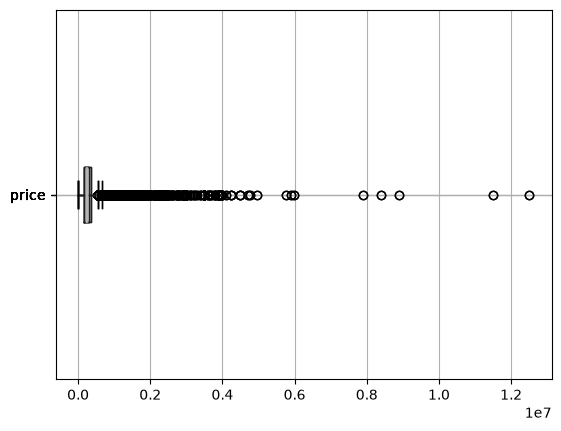

In [18]:
listingdf.boxplot(column="price", vert=False)
plt.show()

Here, I am removing the anomalies by getting the upper whisker of the current dataframe, then recreating the data with just the prices less than that whisker. We can see that the boxplot seems much more reasonable, with the upper whisker now being at ~$575k. This will make the rest of my analysis more understandable, and we have less worry about expensive houses skewing the results.

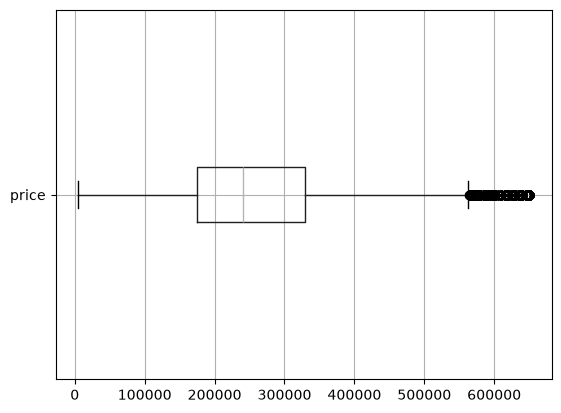

In [32]:
Q1 = listingdf["price"].quantile(0.25)
Q3 = listingdf["price"].quantile(0.75)
IQR = Q3 - Q1

upper_whisker = Q3 + 1.5 * IQR

listingdf = listingdf[listingdf["price"] <= upper_whisker]
listingdf.boxplot(column="price", vert=False)
plt.show()

Now, I want to start doing exploratory data analysis on the crime dataset. I firstly want to change the datatypes of the date fields, then check info() to confirm all looks well. We have some null values in some fields, but not an excessive amount that I would be worried about. I would be comfortable leaving the dataset with just the datatype changes.

In [26]:
crimedf['DateReported'] = pd.to_datetime(crimedf['DateReported'])
crimedf['DateFrom'] = pd.to_datetime(crimedf['DateFrom'])
crimedf['DateTo'] = pd.to_datetime(crimedf['DateTo'])
crimedf.info()

C:\Users\sageb\AppData\Local\Temp\ipykernel_23420\2676257870.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  crimedf['DateReported'] = pd.to_datetime(crimedf['DateReported'])


<class 'pandas.DataFrame'>
RangeIndex: 58938 entries, 0 to 58937
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   INCIDENT_NO       58938 non-null  str           
 1   DateReported      58938 non-null  datetime64[us]
 2   DateFrom          58930 non-null  datetime64[us]
 3   DateTo            58930 non-null  datetime64[us]
 4   BEAT              58699 non-null  str           
 5   CLSD              58430 non-null  str           
 6   STARS_Category    58938 non-null  str           
 7   DAY_OF_WEEK       58938 non-null  str           
 8   CPD_Neighborhood  58699 non-null  str           
 9   Hour_From         58930 non-null  float64       
 10  Hour_To           58930 non-null  float64       
 11  type              58938 non-null  str           
 12  SNA_Neighborhood  58636 non-null  str           
 13  CC_Neighborhood   58677 non-null  str           
 14  ADDRESS_X         57969 non-null 

In [ ]:
# I wanted to investigate what the values of the data might look like.
crimedf.sample(3)

,INCIDENT_NO,DateReported,DateFrom,DateTo,BEAT,CLSD,STARS_Category,DAY_OF_WEEK,CPD_Neighborhood,Hour_From,Hour_To,type,SNA_Neighborhood,CC_Neighborhood,ADDRESS_X,LATITUDE_X,LONGITUDE_X
14059,2025-INC-019327,2025-09-20 17:12:00,2025-09-20 16:00:00,2025-09-20 16:13:00,D4B3,CLEARED_BY_ARREST_ADULT,Part 2,Saturday,AVONDALE,16.00,16.00,Part 2,Avondale,Avondale,35XX DICK ST,39.15,-84.51
24423,2026-INC-002478,2026-02-12 00:08:00,2026-02-11 21:20:00,2026-02-11 21:30:00,D3B2,CLOSED,Robbery,Thursday,WEST PRICE HILL,21.00,21.00,Part 1 Violent,East Price Hill,West Price Hill,19XX WESTMONT LN,39.12,-84.57
54889,2026-INC-002904,2026-02-18 00:12:00,2026-02-17 23:38:00,2026-02-17 23:38:00,D3B3,CLEARED_BY_ARREST_ADULT,Agg Assault,Wednesday,EAST WESTWOOD,23.00,23.00,Part 1 Violent,Millvale,Millvale,20XX WESTWOOD NORTHERN BLVD,39.14,-84.56


Below, I want to look at the number of crimes per neighborhood. This is important because it would tell a potential homebuyer which neighborhoods may be less safe. As we can see, Westwood has the highest count of reported crimes, by far. Downtown, OTR, and Avondale are next in terms of the number of crimes. As a homebuyer, I would be more wary of purchasing in these areas, especially if I were a family with young children.

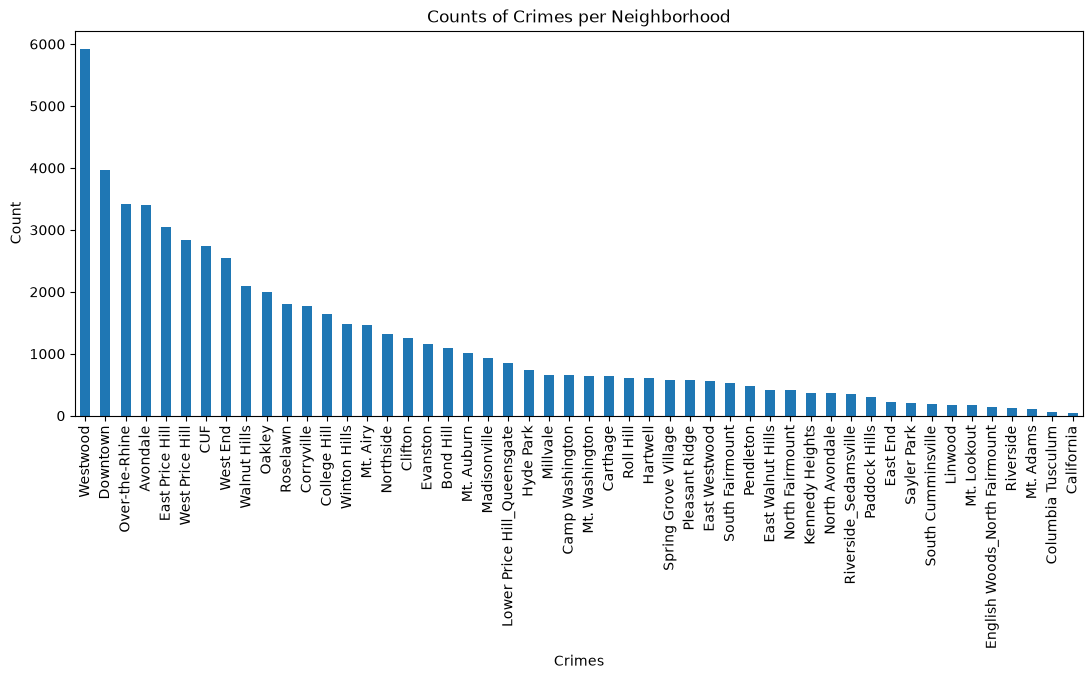

In [28]:
plt.figure(figsize=(13, 5)) 

crimedf['SNA_Neighborhood'].value_counts().plot(kind='bar')

plt.title('Counts of Crimes per Neighborhood')
plt.xlabel('Crimes')
plt.ylabel('Count')

plt.show()

I also wanted to investigate the average listing price per neighborhood. Recall that we removed the outliers, so the data shouldn't be too right-skewed. We can see that the top most-expensive neighborhoods are Hyde Park, Mt. Lookout, and Pendleton. When we look back at the previous barchart for crimes per neighborhood, Hyde Park is in the middle, Mt. Lookout is at the bottom, and Pendleton is in the bottom 75%. We can infer that more expensive neighborhoods may have less crime. Homebuyers may want to investigate a middle range, for a neighborhood that would have median crime and median price, such as Mt. Washington.

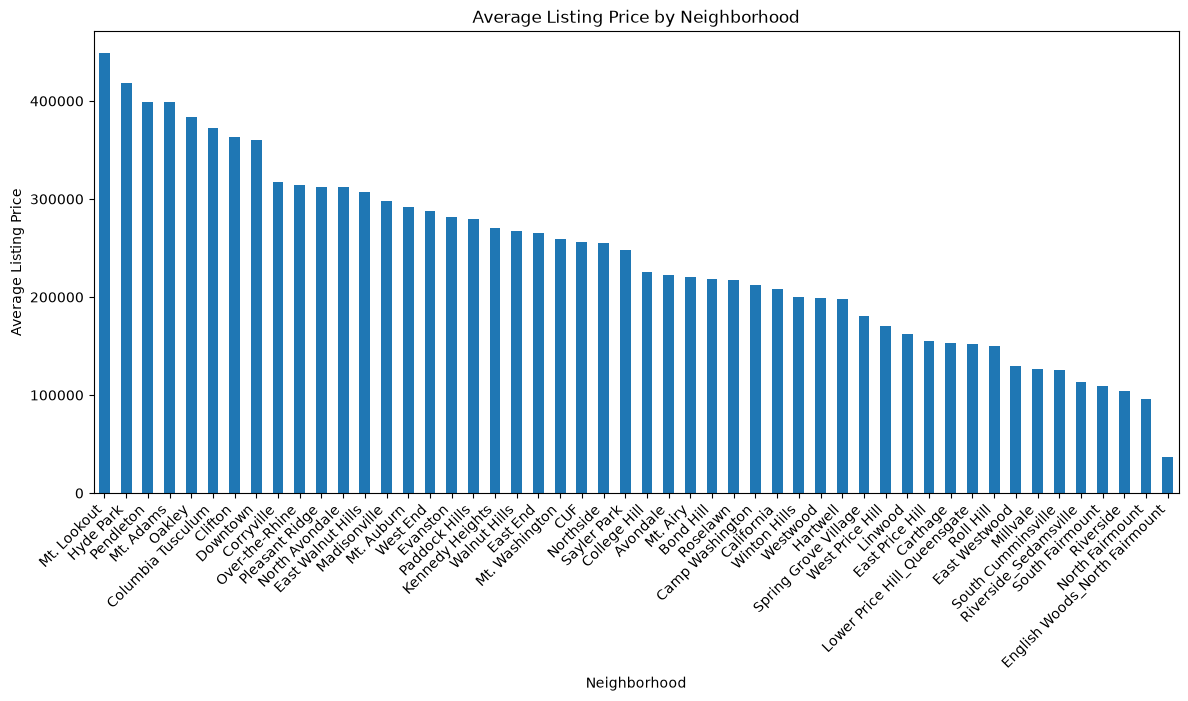

In [37]:
listingdf.groupby("neighborhood")["price"].mean().sort_values(ascending=False).plot(kind="bar", figsize=(14, 6))

plt.title("Average Listing Price by Neighborhood")
plt.xlabel("Neighborhood")
plt.ylabel("Average Listing Price")
plt.xticks(rotation=45, ha="right")

plt.show()

Additionally, I looked at the correlation heatmap to see what were the correlations between all the quantitative features. Shockingly, one of the biggest predictors on price seems to be number of bathrooms, with a correlation on 0.54. Additionally, as square footage increases, so too does the number of bathrooms. I was quite surprised that the correlations were as low/negligible as they were. It could indicate that we just have too much data. Still, if a homebuyer is interested in resale value, it might indicate that the number of bathrooms could be an important factor. 

<Axes: >

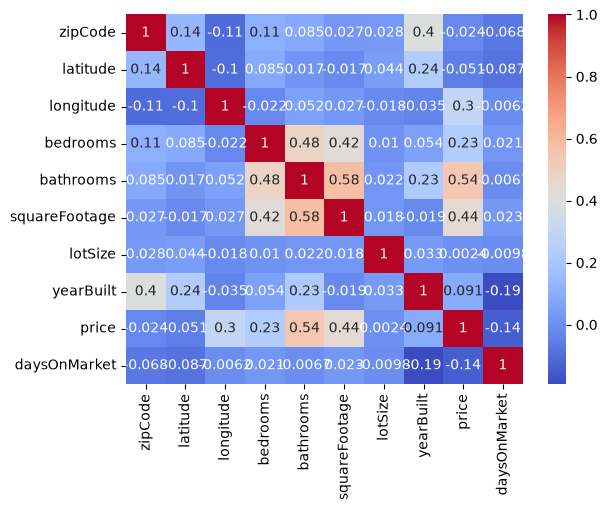

In [38]:
corrmatrix = listingdf.corr(numeric_only=True)
sns.heatmap(corrmatrix, annot=True, cmap='coolwarm')

The first time I ran the code below, there were two extreme outliers priced at 150k but having square footages of 30,000 and 40,000. I decided to remove these records to get a better understanding of the average home. The price is now displaying in scientific notation, but we can see that, generally, as house price increases, so does the square footage. There are some houses where the square footage is significantly higher than what the cost would imply. This could indicate a large home that is in poor condition. Homebuyers might want to stay away from such houses.

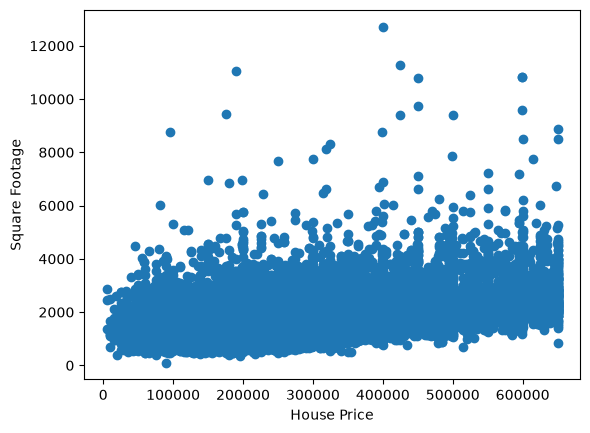

In [33]:
listingdf = listingdf[listingdf["squareFootage"] < 30000]

plt.scatter(x=listingdf["price"], y=listingdf["squareFootage"])
plt.xlabel("House Price")
plt.ylabel("Square Footage")
plt.show()

In the city of Cincinnati, I also wanted to see what types of crimes are most often reported. Part 2 crimes are lower danger crimes, like disorderly conduct, forgery, vandalism, non-aggravated assaults, etc. These crimes seem to make up the majority of the crimes that occur in Cincinnati. Then, theft from a person or a car is the next most common crime. Violent crimes seem to occur less frequently. A future investigation may warrant looking at type of crime per neighborhood—if auto theft happens in specific neighborhoods, a family with multiple cars may wish to avoid moving there.

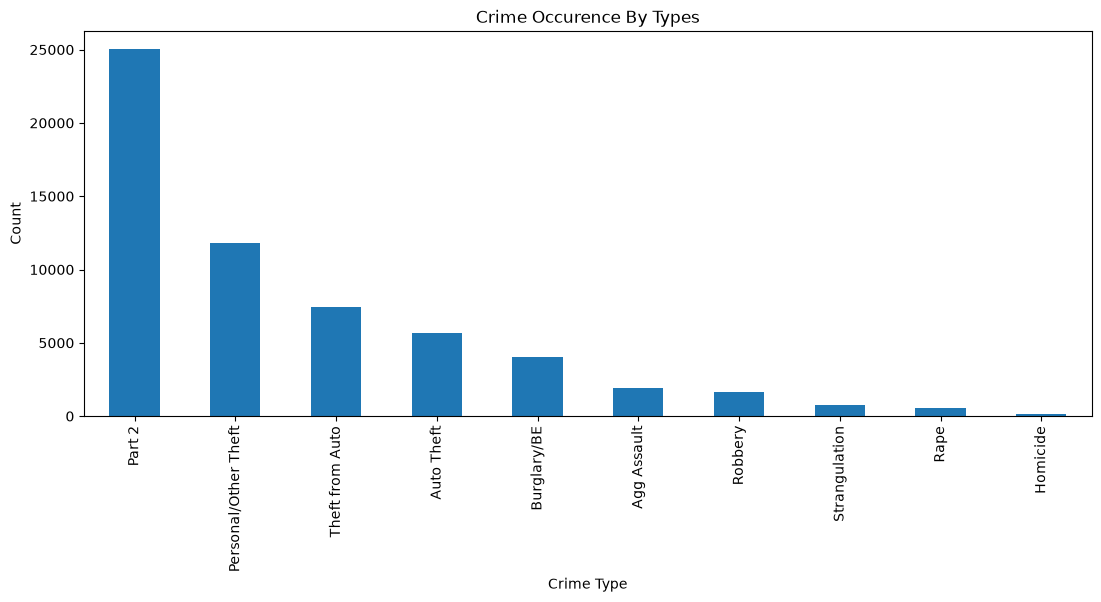

In [34]:
plt.figure(figsize=(13, 5)) 

crimedf['STARS_Category'].value_counts().plot(kind='bar')

plt.title('Crime Occurence By Types')
plt.xlabel('Crime Type')
plt.ylabel('Count')

plt.show()

MACHINE LEARNING PLAN

I plan to use supervised machine learning for this project. House listing data lends itself well to the regression type of machine learning. I want to predict house price based on a number of features, including square footage, year built, number of beds/baths, neighborhood, etc. One aspect with using neighborhood as a feature is that for regression, all the features need to be numeric, so I would have to encode each neighborhood with a number. This should be simple enough to address, and I may need to do it for other categorical variables I decide to utilize. Additionally, I am concerned that the correlation map does not have very high correlations for most features, so I wonder how well I will be able to predict house data. Still, I plan to mitigate this as much as possible by utilizing 75% training, 25% testing data so I can fit the model appropriately. Overall, the EDA and data cleaning segment gave me a good understanding of what the data looks like so I can best pursue an effective machine learning model.


PRIOR FEEDBACK AND UPDATES

I did not receive any feedback from a peer nor from the teaching team for the first part of the project. However, I did have to make some updates to how my listing data was being pulled between the time of the last checkpoint and now. I belatedly realized that the JSON response from the RentCast API was outputting the fields in different orders or omitting some fields, which messed up the generation of the CSV. I had to entirely recreate the listing CSV. I did this by directly mapping the fields I wanted from the API into the Pandas dataframe. This way, I could avoid the columns being offset for the CSV and instead just deal with null values when they appear.

## Resources and References
*What resources and references have you used for this project?*
📝 <!-- Answer Below -->

https://services.arcgis.com/JyZag7oO4NteHGiq/ArcGIS/rest/services/Open_Data_Feature_Collection/FeatureServer/12

https://developers.rentcast.io/reference/introduction

In [35]:
# ⚠️ Make sure you run this cell at the end of your notebook before every submission!
!jupyter nbconvert --to python source.ipynb

[NbConvertApp] Converting notebook source.ipynb to python
[NbConvertApp] Writing 18365 bytes to source.py
